# Pytorch Workflow

end to end workflow



In [292]:
what_were_covering = {1: "data(prepare and load)",
                      2: "build model",
                      3: "fitting the model to data(training)",
                      4: "making prediction and evaluating a model(inference)",
                      5: "saving and loading a model",
                      6: "putting it all together"}

what_were_covering

{1: 'data(prepare and load)',
 2: 'build model',
 3: 'fitting the model to data(training)',
 4: 'making prediction and evaluating a model(inference)',
 5: 'saving and loading a model',
 6: 'putting it all together'}

In [293]:
import torch
from torch import nn # nn contains all of pytorch's building blocks for neural networks
import matplotlib.pyplot as plt

#Check Pytorch Version
torch.__version__

'2.14.0+cpu'

## 1. Data (Preparing and learning)

data can be almost anything ... in machine learning

*Excel spreadsheet
*Images of any kind
*Videos (Youtube for instance)
*Audio like songs or podcasts
*DNA
*Text

Machine learning is a game of two parts
1. Turn data into numbers
2. Build a model to learn patterns in numbers

To showcase this lets create some *known* data using the linear regression formula, using *known* **parameters**

# Y = a +bX

In [294]:
#Create *known* parameters 
weight = 0.7 #b
bias = 0.3 #a

#Create 
start = 0
end = 1
step = 0.02
X = torch.arange(start, end, step).unsqueeze(dim = 1) #Unsqueeze adds extra dimensions, so bsically each square bracket around each number to sperate the data better
y = weight*X + bias

X[:10],y[:10]

(tensor([[0.0000],
         [0.0200],
         [0.0400],
         [0.0600],
         [0.0800],
         [0.1000],
         [0.1200],
         [0.1400],
         [0.1600],
         [0.1800]]),
 tensor([[0.3000],
         [0.3140],
         [0.3280],
         [0.3420],
         [0.3560],
         [0.3700],
         [0.3840],
         [0.3980],
         [0.4120],
         [0.4260]]))

In [295]:
len(X), len(y)

(50, 50)

### Splitting data into training and test sets (one of the most important concpets in machine learning)

Lets create a training and test set with the data

In [296]:
# Create train/test split
train_split = int(0.8 * len(X))
X_train, y_train = X[:train_split], y[:train_split]
X_test, y_test = X[train_split:], y[train_split:]

len(X_train), len(y_train), len(X_test), len(y_test)

(40, 40, 10, 10)

How might we better visualize out data?

This is where the data explorers motto comes in!

"Visualize, visualize, visualize"

In [297]:
def plot_predictions(train_data=X_train,
                     train_labels=y_train,
                     test_data=X_test,
                     test_labels=y_test,
                     predictions=None):
    """
    Plots training data, test data and comapres predicitons.
    """
    plt.figure(figsize=(10, 7))

    # Plot training data
    plt.scatter(train_data, train_labels, c="b", s=4, label="Training data")

    #Plot tests data in green
    plt.scatter(test_data, test_labels, c="g", s=4, label="Testing data")

    # Are there predictions?
    if predictions is not None:
        #Plot the predictions if they exist
        plt.scatter(test_data, predictions, c="r", s=4, label = "Predictions")

        #Show legend
    plt.legend(prop={"size":14});

   

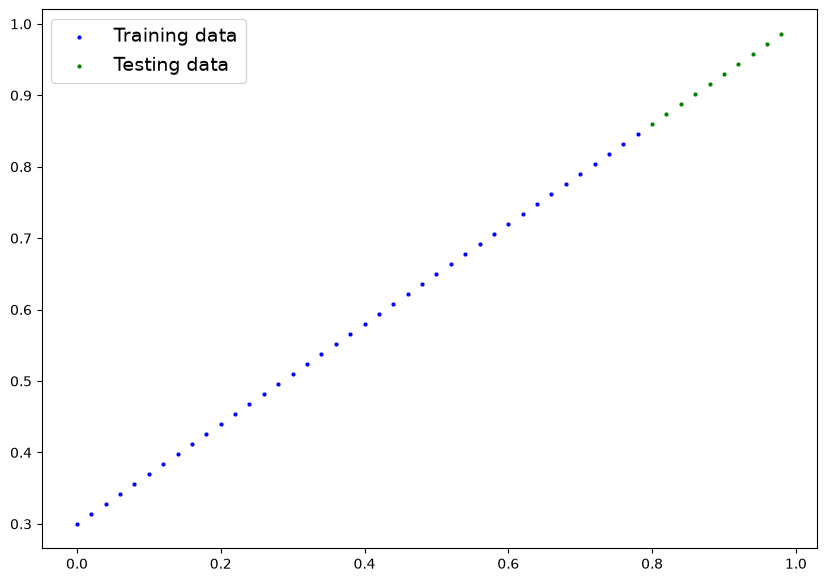

In [298]:
plot_predictions();

## 2. Build model

Our first Pytorch model!

Learn OOP in Python: https://realpython.com/python3-object-oriented-programming/

What our model does:
* start with random values (weight and bias)
* Look at training data and adjust the random values to better represent (or get close to) the ideal values (the weight & bias values we used to create the data)

How does it do so?

Thorugh two main algorithms:
1. Gradient descent
2. Back propagation

In [299]:
# Create a linear regression model class
class LinearRegressionModel(nn.Module): # almost everything in Pytorch inherits it from nn.Module
    def __init__(self):
        super().__init__()
        self.weights = nn.Parameter(torch.randn(1,
                                               requires_grad=True,
                                               dtype=torch.float))
        self.bias = nn.Parameter(torch.randn(1,
                                               requires_grad=True,
                                               dtype=torch.float))
    #Forward method to define the computation in the model
    def forward(self, x: torch.Tensor) -> torch.Tensor: #x is the input data
        return self.weights * x + self.bias #linear Regression Model


### Pytorch Model Building essentials

* torch.nn - contains all of the building blocks for computational graphs (a NN can be considered a computational graph)
* torch.nn.Parameter - what parameters should our model try and learn, often a Pytorch layer from torch.nn will set these for us
* torch.nn.module - the base class for all NN modules, if you subclass it, you should overwrite forward()
* torch.optim - this where Pytoch optimizerz live, they will help with gradient descent
* def forward() - All nn.module subclases require you to overwrite forward(), this method defines waht happens in the forward computation

Pytorch Cheat Sheet:
https://pytorch-cn.com/tutorials/beginner/ptcheat.html

### Checking the contents of our Pytorch model

lets see whats inside the model

so we can check out our model aprameters using ',parameters()'

In [300]:
torch.manual_seed(42)
torch.randn(1)

tensor([0.3367])

In [301]:
#Create random seed
torch.manual_seed(42) #sets intial conditions biscally

#Create instance of the model (this is a subclass of nn.module)
model_0 = LinearRegressionModel()

#CHeck out parameters
list(model_0.parameters())

[Parameter containing:
 tensor([0.3367], requires_grad=True),
 Parameter containing:
 tensor([0.1288], requires_grad=True)]

In [302]:
#List named parameters
model_0.state_dict()


OrderedDict([('weights', tensor([0.3367])), ('bias', tensor([0.1288]))])

### Making prediction using 'torch.inference_mode()'

To check out models predictive power, lets see how well it predicts 'y_test' and 'x_test'.

When we pass data through out model tis going to run it through the forward method

In [303]:
# Make predictiosn with model
with torch.inference_mode(): #This is quicker
    y_preds = model_0(X_test)

#Can use this too but inference mode is favored
# with torch.no_grad():
#     y_preds = model_0(X_test)

y_preds

#NOTimplementederror: probably means an indetation is wrong in the model section

tensor([[0.3982],
        [0.4049],
        [0.4116],
        [0.4184],
        [0.4251],
        [0.4318],
        [0.4386],
        [0.4453],
        [0.4520],
        [0.4588]])

In [304]:
y_test

tensor([[0.8600],
        [0.8740],
        [0.8880],
        [0.9020],
        [0.9160],
        [0.9300],
        [0.9440],
        [0.9580],
        [0.9720],
        [0.9860]])

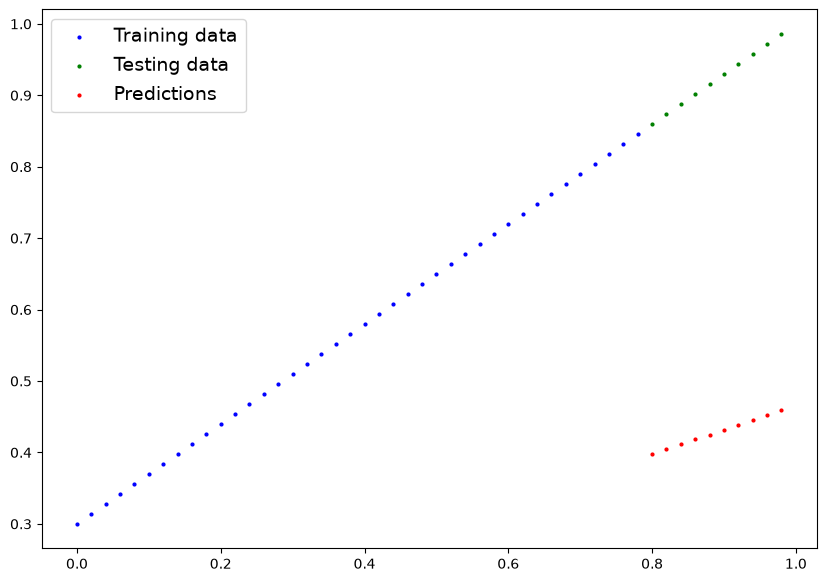

In [305]:
plot_predictions(predictions=y_preds)

## 3. Train Model

The whole idea of training is for a model to moce from some unknown parameters (may be random) to some known parameters

Or in other words from a poor representation of the data to a better one

One way to measure how poor or how wrong your models predictions are is to us a loss fucniton

* Note: Loss function may be called cost fucntion or criterion in different areas. For our case we will refer to it as a loss fucntion

Things we need to train:

* **Loss function:** A function to measure how wrong your model's predictions are to the real outputs, lower is better.
* **Optimizer:** Takes into account the loss of a model and adjusts the models parameters, in our case to improve the loss function.

Hyperparameter: I set it myself

Parameter: model sets it

And specifically for Pytorch, we need:

* Training loop
* Testing loop

In [306]:
list(model_0.parameters())

[Parameter containing:
 tensor([0.3367], requires_grad=True),
 Parameter containing:
 tensor([0.1288], requires_grad=True)]

In [307]:
model_0.state_dict()

OrderedDict([('weights', tensor([0.3367])), ('bias', tensor([0.1288]))])

In [308]:
# Set up a loss function
loss_fn = nn.L1Loss()

# Setup an optimizer (Adam or SGD  is built optimizer)# Stocahstic gradient descent

optimizer = torch.optim.SGD(params = model_0.parameters(),
                            lr = 0.01) #lr = learning rate, possibly the most important hyperparameter


### Building a training loop (and a testing loop) in Pytorch

A couple of things needed for a training loop:
0. Loop through the data
1. Forward pass (this involves data moving through out models forward() functions) to make predictions on data
2. Calculate the loss (comapre forward pass predictions to ground truth labels)
3. Optimizer zero grad
4. Loss backward - move backwards through the network to calculate the gradients of each of the parameters of our model with respect to the loss (**backpropagation**)
5. Optimizer step - use the optimizer to adjsut our models parameters to reduce the loss(**gradient descent**)


In [309]:
torch.manual_seed(42)

# An epoch is one loop through the data
epochs = 200 #Hyperparameter

epoch_count = []
loss_values = []
test_loss_values = []

### Training
# 0. Loop through data
for epochs in range(epochs):
    # Set the model to training mode
    model_0.train() #train mode in Pytorch sets all parameters that require gradients to require gradients

    #1. Forward pass
    y_pred = model_0(X_train)

    # 2. Calculate the loss
    loss = loss_fn(y_pred,y_train)
    #print(f"Loss: {loss} ")

    # 3. Optimizer zero grad
    optimizer.zero_grad()

    # 4.Backward propagation on the loss with respect to the parameters of the model
    loss.backward()

    # 5. Step the optimizer (perform gradient descent)
    optimizer.step() #by default how the optimizer cahnges will accumulate through the loop... we have to zero them above in step 3

    ###Testing
    model_0.eval() #turns off settign in model not needs for evaluation/testing (dropout/batch norm layers)
    with torch.inference_mode(): #turns off gradient tracking for inference/testing
        #1. Do the forward pass 
        y_pred_test = model_0(X_test)

        # 2. Calculate the Loss
        test_loss = loss_fn(y_pred_test, y_test)


    if epochs % 10 == 0: # Print every 10 epochs
        # Append the current epoch and loss values to the lists
        epoch_count.append(epochs) #Items makes it so matplotlib can be used
        loss_values.append(loss.item())
        test_loss_values.append(test_loss.item())
        print(f"Epoch: {epochs} | Loss: {loss} | Test loss: {test_loss}")

        print(model_0.state_dict())

Epoch: 0 | Loss: 0.31288138031959534 | Test loss: 0.48106518387794495
OrderedDict({'weights': tensor([0.3406]), 'bias': tensor([0.1388])})
Epoch: 10 | Loss: 0.1976713240146637 | Test loss: 0.3463551998138428
OrderedDict({'weights': tensor([0.3796]), 'bias': tensor([0.2388])})
Epoch: 20 | Loss: 0.08908725529909134 | Test loss: 0.21729660034179688
OrderedDict({'weights': tensor([0.4184]), 'bias': tensor([0.3333])})
Epoch: 30 | Loss: 0.053148526698350906 | Test loss: 0.14464017748832703
OrderedDict({'weights': tensor([0.4512]), 'bias': tensor([0.3768])})
Epoch: 40 | Loss: 0.04543796554207802 | Test loss: 0.11360953003168106
OrderedDict({'weights': tensor([0.4748]), 'bias': tensor([0.3868])})
Epoch: 50 | Loss: 0.04167863354086876 | Test loss: 0.09919948130846024
OrderedDict({'weights': tensor([0.4938]), 'bias': tensor([0.3843])})
Epoch: 60 | Loss: 0.03818932920694351 | Test loss: 0.08886633068323135
OrderedDict({'weights': tensor([0.5116]), 'bias': tensor([0.3788])})
Epoch: 70 | Loss: 0.03

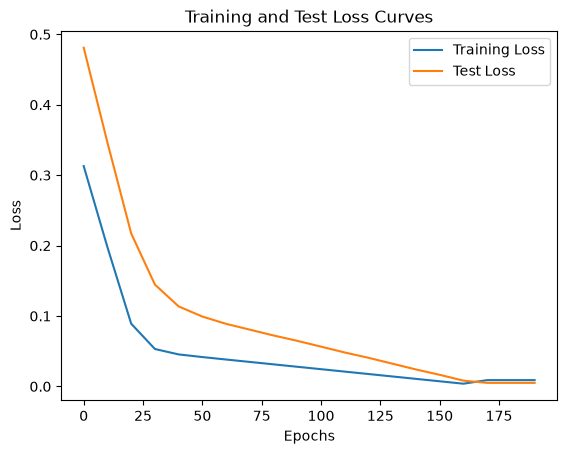

In [310]:
#Plot the loss curves

plt.plot(epoch_count, loss_values, label="Training Loss")
plt.plot(epoch_count, test_loss_values, label="Test Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training and Test Loss Curves")
plt.legend()
plt.show()

In [311]:
with torch.inference_mode():
    y_pred_new = model_0(X_test)

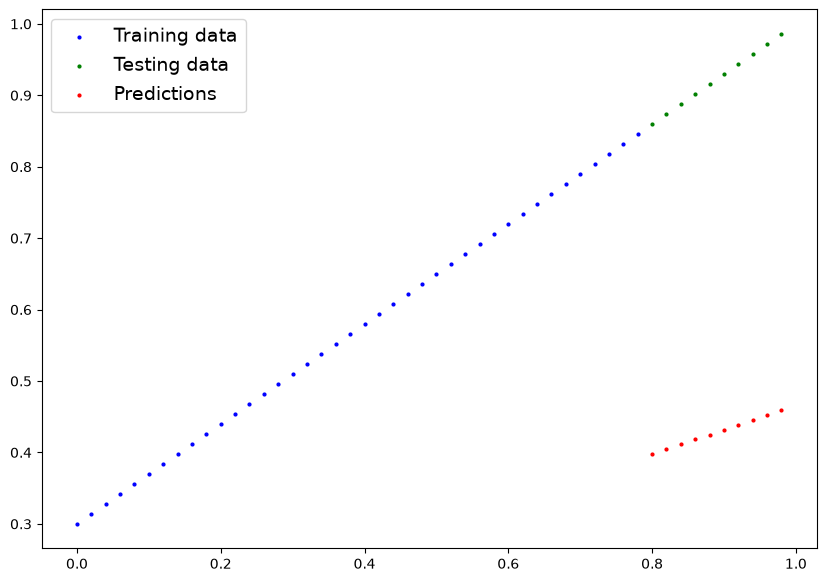

In [312]:
plot_predictions(predictions=y_preds)

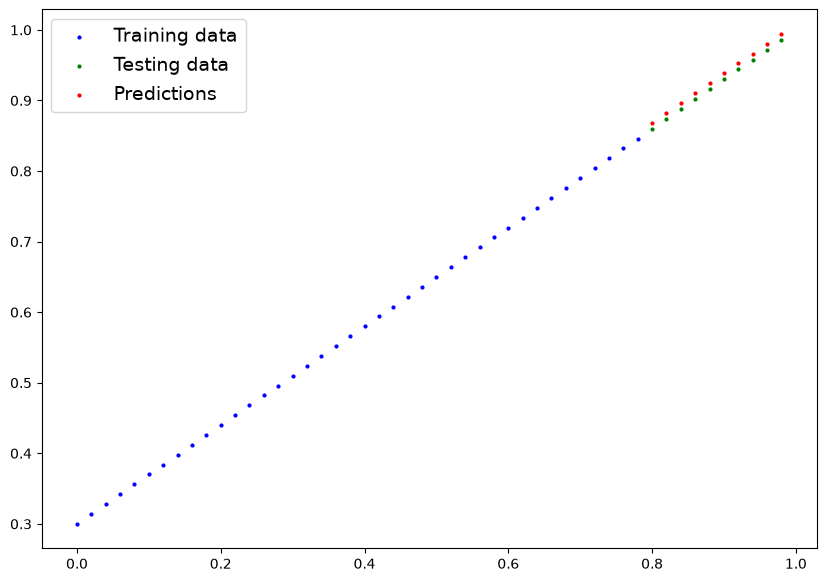

In [313]:
plot_predictions(predictions=y_pred_new)

## Saving a model in Pytorch

There are three maon methods you should about for saving and loading modesl

1. 'torch.save()'
2. 'torch.load()'
3. torch.nn.Module.load_state_dict - this allows to load a models ssaved state dictionary



In [314]:
#Saving a model in Pytorch
from pathlib import Path

#create models directory
MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)

#define the model save path
MODEL_NAME = "model_0.pth"
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME

#save the model state dict
print(f"Saving model to: {MODEL_SAVE_PATH}")
torch.save(model_0.state_dict(), MODEL_SAVE_PATH)

Saving model to: models\model_0.pth


In [315]:
model_0.state_dict()

OrderedDict([('weights', tensor([0.6990])), ('bias', tensor([0.3093]))])

In [316]:
# Instantiate the model before loading the state dict

loaded_model_0 = LinearRegressionModel()

#Load saved state dict of model 0
loaded_model_0.load_state_dict(torch.load(f=MODEL_SAVE_PATH))


<All keys matched successfully>

In [317]:
loaded_model_0.state_dict()

OrderedDict([('weights', tensor([0.6990])), ('bias', tensor([0.3093]))])

In [318]:
#Make soem predictions with loaded model
loaded_model_0.eval()
with torch.inference_mode():
    loaded_model_preds = loaded_model_0(X_test)

loaded_model_preds

tensor([[0.8685],
        [0.8825],
        [0.8965],
        [0.9105],
        [0.9245],
        [0.9384],
        [0.9524],
        [0.9664],
        [0.9804],
        [0.9944]])

In [319]:
#Make some models preds
model_0.eval()
with torch.inference_mode():
    y_preds = model_0(X_test)

y_preds

tensor([[0.8685],
        [0.8825],
        [0.8965],
        [0.9105],
        [0.9245],
        [0.9384],
        [0.9524],
        [0.9664],
        [0.9804],
        [0.9944]])

In [320]:
# Compare laoded model with original model
y_preds == loaded_model_preds

tensor([[True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True]])

## 6. Putting it all together

Lets go back through the steps above

In [321]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.__version__

'2.14.0+cpu'

Create device-agnostic code

This means that is we have access to a gpu, out code will use it (for potentially fater computing)

If no gpu the default to cpu

In [322]:
#Setup device agnostic code
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cpu


### 6.1 Data

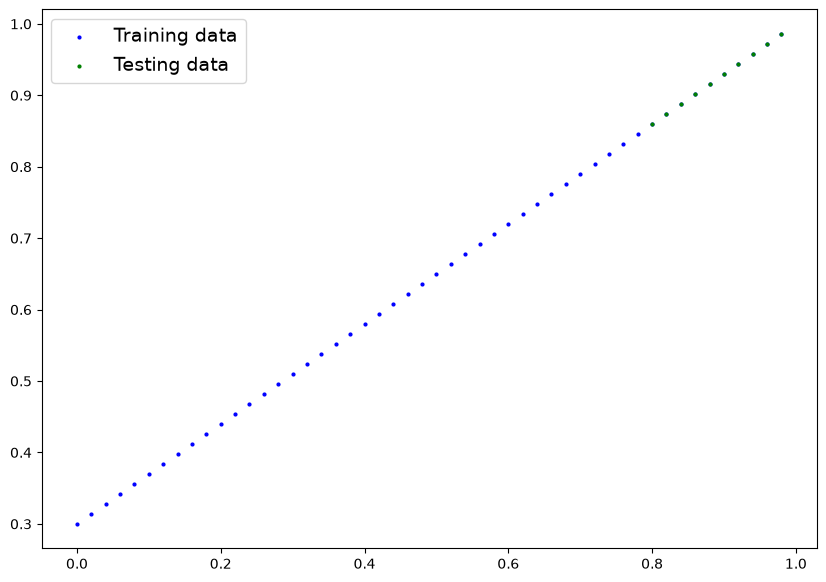

In [323]:
#Crerate some data useing the linear regression formula Y = M*x+B
weight = 0.7
bias = 0.3

#Cerate range values
start = 0
end = 1
step = 0.02

#Create the input data
X = torch.arange(start, end, step).unsqueeze(dim=1)

#Create the output data
y = weight * X + bias

plot_predictions(X, y)


### 6.2 building model

In [324]:
class LinearRegressionModelV2(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Linear(in_features=1, out_features=1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.linear(x)

torch.manual_seed(42)
model_1 = LinearRegressionModelV2()
model_1.state_dict()

OrderedDict([('linear.weight', tensor([[0.7645]])),
             ('linear.bias', tensor([0.8300]))])

In [325]:
X_train[:5], y_train[:5]

(tensor([[0.0000],
         [0.0200],
         [0.0400],
         [0.0600],
         [0.0800]]),
 tensor([[0.3000],
         [0.3140],
         [0.3280],
         [0.3420],
         [0.3560]]))

In [326]:
#Check model current device
next(model_1.parameters()).device

device(type='cpu')

In [327]:
# Set the model to use the target device
model_1.to(device)

LinearRegressionModelV2(
  (linear): Linear(in_features=1, out_features=1, bias=True)
)

### 6.3 Training

* Loss function
* Optimizer
* training loop
* testing loop

In [328]:
# Setup loss fucntion

lonn_fn = nn.L1Loss()

#Optimizer

optimizer = torch.optim.SGD(params=model_1.parameters(), lr=0.01)

In [329]:
# Training loop
torch.manual_seed(42)

epochs = 200

# Put data to device so that it is all the same (Doesnt matter for running code on my cpu)
X_train  = X_train.to(device)
y_train = y_train.to(device)
X_test = X_test.to(device)
y_test = y_test.to(device)

for epoch in range(epochs):
    model_1.train()

    y_pred = model_1(X_train)

    loss = loss_fn(y_pred, y_train)

    optimizer.zero_grad()

    loss.backward()
    
    optimizer.step()

    ### testing
    model_1.eval()
    with torch.inference_mode():
        test_pred = model_1(X_test)
        test_loss = loss_fn(test_pred, y_test)

    if epoch % 10 == 0:
        print(f"Epoch: {epoch} | Train Loss: {loss} | Test Loss: {test_loss.item()}")

Epoch: 0 | Train Loss: 0.5551779866218567 | Test Loss: 0.5739762187004089
Epoch: 10 | Train Loss: 0.4399680495262146 | Test Loss: 0.4392663538455963
Epoch: 20 | Train Loss: 0.3247582018375397 | Test Loss: 0.30455657839775085
Epoch: 30 | Train Loss: 0.20954827964305878 | Test Loss: 0.16984674334526062
Epoch: 40 | Train Loss: 0.09433844685554504 | Test Loss: 0.03513689711689949
Epoch: 50 | Train Loss: 0.023886386305093765 | Test Loss: 0.04784906655550003
Epoch: 60 | Train Loss: 0.0199567973613739 | Test Loss: 0.04580312222242355
Epoch: 70 | Train Loss: 0.016517987474799156 | Test Loss: 0.0375305712223053
Epoch: 80 | Train Loss: 0.013089170679450035 | Test Loss: 0.029944902285933495
Epoch: 90 | Train Loss: 0.009653178043663502 | Test Loss: 0.02167237363755703
Epoch: 100 | Train Loss: 0.006215679459273815 | Test Loss: 0.014086711220443249
Epoch: 110 | Train Loss: 0.002787243574857712 | Test Loss: 0.005814164876937866
Epoch: 120 | Train Loss: 0.0012645035749301314 | Test Loss: 0.01380180753

In [330]:
model_1.state_dict()

OrderedDict([('linear.weight', tensor([[0.6968]])),
             ('linear.bias', tensor([0.3025]))])

### 6.4 Making and evaluation predictions

In [331]:
model_1.eval()

with torch.inference_mode():
    y_preds = model_1(X_test)
y_preds

tensor([[0.8600],
        [0.8739],
        [0.8878],
        [0.9018],
        [0.9157],
        [0.9296],
        [0.9436],
        [0.9575],
        [0.9714],
        [0.9854]])

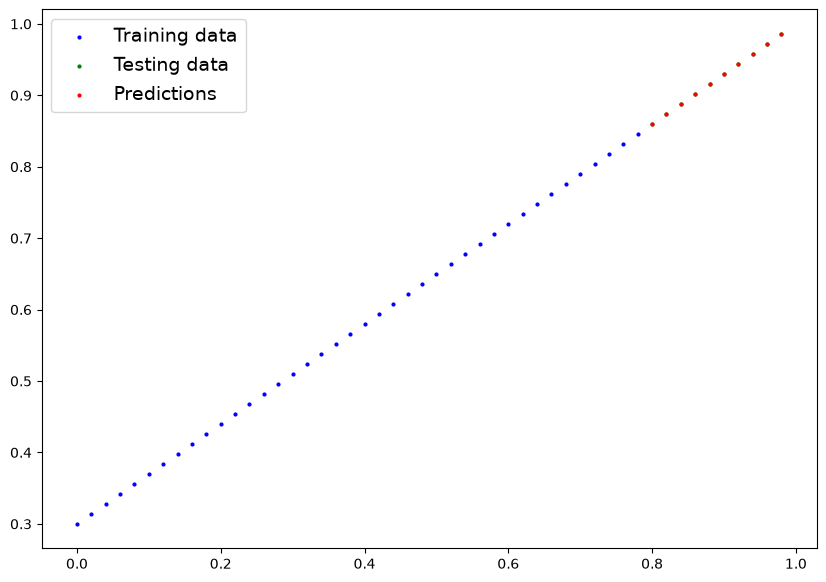

In [332]:
plot_predictions(predictions= y_preds.cpu())

### 6.5 saving and loading model

In [333]:
from pathlib import Path

model_path = Path("models")
model_path.mkdir(parents=True, exist_ok=True)


model_name = "model_1.pth"
model_save_path = model_path / model_name

print(f"Saving model to: {model_save_path}")
torch.save(obj=model_1.state_dict(), f=model_save_path)
#torch.save(model_1.state_dict(), model_save_path)

Saving model to: models\model_1.pth


In [334]:
# Load a Model

loaded_model_1 = LinearRegressionModelV2()

# Load the saved model 1 state dict
loaded_model_1.load_state_dict(torch.load(model_save_path))

#Put loaded mdoel to device
loaded_model_1.to(device)

LinearRegressionModelV2(
  (linear): Linear(in_features=1, out_features=1, bias=True)
)

In [335]:
next(loaded_model_1.parameters()).device

device(type='cpu')

In [336]:
loaded_model_1.state_dict()

OrderedDict([('linear.weight', tensor([[0.6968]])),
             ('linear.bias', tensor([0.3025]))])

In [337]:
#Eval loaded model
loaded_model_1.eval()
with torch.inference_mode():
    loaded_model_1_pred = loaded_model_1(X_test)
y_preds == loaded_model_1_pred

tensor([[True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True]])

### Classification!!!!

In [338]:
## 1. Data 
import sklearn
from sklearn.datasets import make_circles

n_samples = 1000

X, y = make_circles(n_samples, noise = 0.03, random_state = 42)

In [339]:
len(X), len(y)

(1000, 1000)

In [340]:
print(f"First five samples of X:\n {X[:5]}")
print(f"First five samples of y:\n {y[:5]}")  

First five samples of X:
 [[ 0.75424625  0.23148074]
 [-0.75615888  0.15325888]
 [-0.81539193  0.17328203]
 [-0.39373073  0.69288277]
 [ 0.44220765 -0.89672343]]
First five samples of y:
 [1 1 1 1 0]


In [341]:
#Make a data frame of circle data
import pandas as pd

circles = pd.DataFrame({"X1":X[:,0], 
                        "X2":X[:,1], 
                        "Label":y})

circles.head(10)

,X1,X2,Label
0,0.754246,0.231481,1
1,-0.756159,0.153259,1
2,-0.815392,0.173282,1
3,-0.393731,0.692883,1
4,0.442208,-0.896723,0
5,-0.479646,0.676435,1
6,-0.013648,0.803349,1
7,0.771513,0.147760,1
8,-0.169322,-0.793456,1
9,-0.121486,1.021509,0


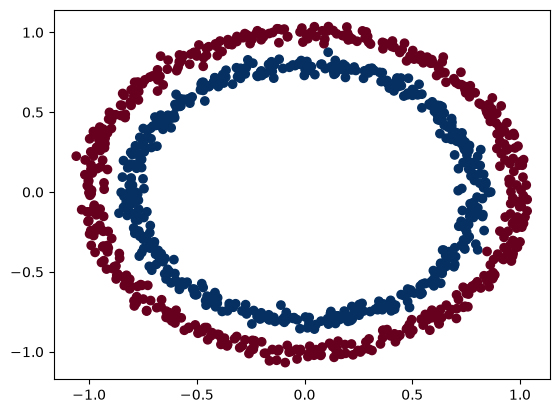

In [342]:
# Visualize
import matplotlib.pyplot as plt

plt.scatter(x=X[:,0],
            y=X[:,1],
            c=y,
            cmap=plt.cm.RdBu)

### 1.1 Check input and output shapes

In [343]:
X.shape, y.shape

((1000, 2), (1000,))

In [344]:
#View the first example of features and labels

X_sample = X[0]
y_sample = y[0]

print(f"Values for one sample of X: {X_sample}, y: {y_sample}")
print(f"Shape of X: {X_sample.shape}, Shape of y: {y_sample.shape}")

Values for one sample of X: [0.75424625 0.23148074], y: 1
Shape of X: (2,), Shape of y: ()


### 1.2 turn data into tensors and train/test splits


In [345]:
#Turn data into tensors
import torch
torch.__version__

'2.14.0+cpu'

In [ ]:
type(X) #already a tensor? Rerun all code



numpy.ndarray

In [347]:
# turn data into tensors
X = torch.from_numpy(X).type(torch.float)
y = torch.from_numpy(y).type(torch.float)

X[:5],y[:5]

(tensor([[ 0.7542,  0.2315],
         [-0.7562,  0.1533],
         [-0.8154,  0.1733],
         [-0.3937,  0.6929],
         [ 0.4422, -0.8967]]),
 tensor([1., 1., 1., 1., 0.]))

In [348]:
from sklearn.model_selection import train_test_split
#ORDER MATTERS 
X_train, X_test, y_train, y_test = train_test_split(X, y, 
                                                    test_size=0.2 # # 20% of data will be test
                                                    , random_state=42) # for reproducibility

In [350]:
len(X_train),len(X_test), len(y_train),len(y_test)

(800, 200, 800, 200)

## 2. Building a model

In [352]:
import torch
from torch import nn

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"The device is {device}")

The device is cpu


In [355]:
# 1. Contruct a model that subclasses nn.module

class CircleModelV0(nn.Module):
    def __init__(self):
        super().__init__()
        #2. create 2 nn.linear layers
        self.layer1 = nn.Linear(in_features = 2, out_features = 5)
        self.layer2 = nn.Linear(in_features = 5, out_features = 1)

    def forward(self, x):
        return self.layer2(self.layer1(x))

## Instantiate the model
model_circle = CircleModelV0().to(device)
model_circle


CircleModelV0(
  (layer1): Linear(in_features=2, out_features=5, bias=True)
  (layer2): Linear(in_features=5, out_features=1, bias=True)
)